# 2.3 Ripley's K: are HDB blocks and childcare centres clustered?

Before relating supply to demand we check how each point pattern is arranged on its own. Ripley's
K-function counts, for every radius *r*, the expected number of other points within *r* of a
typical point, scaled by the overall intensity: under complete spatial randomness (CSR, a
homogeneous Poisson process) K(r) = pi r², so a curve above that reference means more neighbours
than chance (clustering) and below it means regularity. We run it for the 10,769 residential HDB
blocks and for the 1,796 centres, each against 199 CSR simulations inside the dissolved MP2019
land boundary, with a border correction and a global Monte Carlo test.

Original author: Karis (cell 23 of `walking_network_analysis/osrm_walking_query.ipynb`), scripted
by Minh as `scripts/k_function.py` and rerun on the canonical centre layer. Converted 2026-11-10
with one addition: an L(r) − r plot, because on the K scale the CSR band is a hairline.

**Inputs**
- `data/MasterPlanSubZones_2019.geojson` (study window; dissolved, EPSG:3414)
- `output/hdb_blocks.gpkg`, layer `hdb_points` (10,769 residential block centroids; stage 1)
- `output/childcare_centres_2026.gpkg`, layer `centres` (1,796 centres; Jessie)

**Outputs** (all in `output/k_function/`, used by the report and the stage README)
- `hdbs_k_curve.csv`, `childcare_centres_k_curve.csv` (observed K, L − r and CSR bands per radius)
- `hdbs_csr_simulations.npz`, `childcare_centres_csr_simulations.npz` (the 199 simulated L − r curves)
- `k_summary.csv` (audit counts, max L − r, global and Bonferroni p-values)
- `k_function_comparison.png` (K scale), `l_function_comparison.png` (L − r scale)

Runtime about one minute (two patterns × 199 simulations of a border-corrected K).

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "bt4015").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from bt4015.paths import DATA, OUT, FIG, LARGE

import time
import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
from scipy.spatial import cKDTree
import matplotlib.pyplot as plt

# Fixed figure palette (docs/notebook_style.md): categorical order blue, orange, aqua, yellow;
# sequential = single-hue Blues; text in dark grey, never in a series colour.
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK2, GRID, SURF = "#333333", "#52514e", "#e6e5e1", "#ffffff"
plt.rcParams.update({"text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2,
                     "ytick.color": INK2, "axes.edgecolor": GRID, "figure.facecolor": SURF,
                     "savefig.facecolor": SURF, "font.size": 9})

K_RADII = np.arange(100, 1501, 100, dtype=float)   # 100 m to 1.5 km in 100 m steps (walking scale)
K_NSIM = 199                                       # CSR simulations: (1 + 199) gives p in steps of 0.005
K_SEED = 4015                                      # repo seed; one child stream per pattern
K_OUT = OUT / "k_function"
K_OUT.mkdir(parents=True, exist_ok=True)

## 1. Study window

The window is the dissolved MP2019 subzone layer in SVY21 metres. Points outside it (none here)
would be dropped. For the border correction we pre-compute the window eroded by each radius: a
focal point only counts if its whole radius-*r* disc lies inside the window, while every in-window
point can be a neighbour. This is the simplest exact edge correction and is what the original cell
used.

In [2]:
# 1. Dissolve the subzones (make_valid first: a few MP2019 rings self-touch).
k_subzones = gpd.read_file(DATA / "MasterPlanSubZones_2019.geojson").to_crs(3414)
k_window = shapely.union_all(shapely.make_valid(k_subzones.geometry.to_numpy()))
assert not k_window.is_empty and k_window.area > 0, "Study window must have positive area."

# 2. Eroded windows, one per radius, prepared for fast contains tests.
k_inner_windows = [k_window.buffer(-float(r)) for r in K_RADII]
for inner in k_inner_windows:
    assert not inner.is_empty, "A radius exceeds the available interior of the study window."
    shapely.prepare(inner)
shapely.prepare(k_window)
k_area, k_bounds = k_window.area, k_window.bounds
print(f"window area {k_area / 1e6:,.1f} km2; interior at r = 1,500 m: {k_inner_windows[-1].area / 1e6:,.1f} km2")

window area 784.8 km2; interior at r = 1,500 m: 400.3 km2


## 2. Estimator and simulator

`k_border` is the border-corrected K: for each radius, the number of other points within *r* of
every eligible focal point, normalised by `area / ((n − 1) × eligible count)`. Coincident records
(centres sharing an address) are kept as separate points, so the focal point subtracts only itself.
`k_uniform_points` draws CSR patterns with the same number of points by rejection sampling inside
the window.

In [3]:
def k_load_points(path, layer=None):
    """Point coordinates inside the window plus an audit dict (invalid, outside, coincident)."""
    frame = gpd.read_file(path, **({"layer": layer} if layer else {})).to_crs(3414)
    valid = frame.geometry.notna() & ~frame.geometry.is_empty & frame.geom_type.eq("Point")
    candidates = frame.loc[valid]
    inside = shapely.covers(k_window, candidates.geometry.to_numpy())
    kept = candidates.loc[inside]
    xy = np.column_stack([kept.geometry.x, kept.geometry.y])
    assert len(xy) >= 2, "At least two in-window points are required."
    audit = {"input_n": len(frame), "invalid_or_nonpoint_n": int((~valid).sum()),
             "outside_window_n": int((~inside).sum()), "analysed_n": len(xy),
             "coincident_extra_records": len(xy) - len(np.unique(xy, axis=0))}
    return xy, audit


def k_border(xy):
    """Border-corrected K(r) for each radius in K_RADII, and the eligible focal count per radius."""
    tree = cKDTree(xy)
    values, eligible_counts = [], []
    for radius, inner in zip(K_RADII, k_inner_windows):
        eligible = shapely.contains_xy(inner, xy[:, 0], xy[:, 1])
        count = int(eligible.sum())
        assert count > 0, f"No eligible focal points at radius {radius} m."
        # Subtract each focal point itself, retaining other coincident records.
        neighbours = tree.query_ball_point(xy[eligible], radius, return_length=True) - 1
        values.append(k_area * neighbours.sum() / ((len(xy) - 1) * count))
        eligible_counts.append(count)
    return np.asarray(values), np.asarray(eligible_counts)


def k_uniform_points(n, rng):
    """n uniform points inside the window (rejection sampling from the bounding box)."""
    xmin, ymin, xmax, ymax = k_bounds
    acceptance = k_area / ((xmax - xmin) * (ymax - ymin))
    chunks, remaining = [], n
    while remaining:
        size = max(256, int(np.ceil(remaining / acceptance * 1.1)))
        batch = rng.uniform([xmin, ymin], [xmax, ymax], size=(size, 2))
        accepted = batch[shapely.contains_xy(k_window, batch[:, 0], batch[:, 1])][:remaining]
        chunks.append(accepted)
        remaining -= len(accepted)
    return np.vstack(chunks)

## 3. Load the two point patterns

In [4]:
k_patterns = {
    "HDBs": k_load_points(OUT / "hdb_blocks.gpkg", layer="hdb_points"),
    "Childcare centres": k_load_points(OUT / "childcare_centres_2026.gpkg", layer="centres"),
}
for name, (xy, audit) in k_patterns.items():
    print(name, audit)

HDBs {'input_n': 10769, 'invalid_or_nonpoint_n': 0, 'outside_window_n': 0, 'analysed_n': 10769, 'coincident_extra_records': 0}
Childcare centres {'input_n': 1796, 'invalid_or_nonpoint_n': 0, 'outside_window_n': 0, 'analysed_n': 1796, 'coincident_extra_records': 80}


## 4. Observed K and 199 CSR simulations per pattern

The global test statistic is max over the radii of L(r) − r, where L(r) = sqrt(K(r) / pi) turns
the CSR reference into the horizontal line 0. Its Monte Carlo p-value is
(1 + #simulations with a larger maximum) / 200; with two patterns tested, the Bonferroni-adjusted
p is doubled. The 2.5% / 97.5% quantiles of the simulated L − r at each radius give a descriptive
pointwise band; the fifth-largest simulated maximum (2.5% upper tail of 200) is the global
boundary.

In [5]:
k_results, k_rows = {}, []
t0 = time.time()
for (name, (xy, audit)), seed in zip(k_patterns.items(), np.random.SeedSequence(K_SEED).spawn(2)):
    rng = np.random.default_rng(seed)
    # 1. Observed curve.
    observed_k, eligible = k_border(xy)
    observed_l = np.sqrt(observed_k / np.pi) - K_RADII
    # 2. CSR envelope with the same point count, window and estimator.
    simulated_l = []
    for _ in range(K_NSIM):
        simulated_k, _ = k_border(k_uniform_points(len(xy), rng))
        simulated_l.append(np.sqrt(simulated_k / np.pi) - K_RADII)
    simulated_l = np.asarray(simulated_l)
    # 3. Global one-sided test on max(L - r).
    simulated_max = simulated_l.max(axis=1)
    observed_max = observed_l.max()
    p_value = (1 + np.count_nonzero(simulated_max >= observed_max)) / (K_NSIM + 1)
    # With 199 simulations, the fifth-largest maximum gives a 2.5% upper-tail test.
    tail_count = int(np.floor(0.025 * (K_NSIM + 1)))
    global_upper = np.sort(simulated_max)[-tail_count]
    lower, upper = np.quantile(simulated_l, [0.025, 0.975], axis=0)
    # 4. Save the curve and the simulations (the plots below read them back).
    table = pd.DataFrame({"radius_m": K_RADII, "K_m2": observed_k, "L_minus_r_m": observed_l,
                          "eligible_focal_n": eligible, "CSR_pointwise_lower_m": lower,
                          "CSR_pointwise_upper_m": upper, "global_upper_2pattern_m": global_upper})
    slug = name.lower().replace(" ", "_")
    table.to_csv(K_OUT / f"{slug}_k_curve.csv", index=False)
    np.savez_compressed(K_OUT / f"{slug}_csr_simulations.npz", radii_m=K_RADII, simulated_L_minus_r_m=simulated_l)
    k_results[name] = table
    k_rows.append({"pattern": name, **audit, "window_km2": k_area / 1e6, "simulations": K_NSIM,
                   "max_L_minus_r_m": observed_max, "global_p": p_value,
                   "bonferroni_p": min(1.0, 2 * p_value),
                   "significant_clustering_5pct": min(1.0, 2 * p_value) <= 0.05})
    print(f"{name}: max L(r)-r = {observed_max:,.0f} m at r = {K_RADII[observed_l.argmax()]:.0f} m; "
          f"largest simulated max = {simulated_max.max():,.0f} m; p = {p_value:.3f}  "
          f"[{time.time() - t0:.0f} s]")

HDBs: max L(r)-r = 1,456 m at r = 1500 m; largest simulated max = 12 m; p = 0.005  [40 s]


Childcare centres: max L(r)-r = 1,050 m at r = 1500 m; largest simulated max = 38 m; p = 0.005  [44 s]


In [6]:
k_summary = pd.DataFrame(k_rows).set_index("pattern")
k_summary.to_csv(K_OUT / "k_summary.csv")
print(k_summary.T.to_string())
print()
for name, table in k_results.items():
    print(f"{name}: L(r)-r by radius (m)")
    print(table[["radius_m", "L_minus_r_m", "CSR_pointwise_upper_m", "eligible_focal_n"]].round(1).to_string(index=False))

pattern                             HDBs Childcare centres
input_n                            10769              1796
invalid_or_nonpoint_n                  0                 0
outside_window_n                       0                 0
analysed_n                         10769              1796
coincident_extra_records               0                80
window_km2                    784.784012        784.784012
simulations                          199               199
max_L_minus_r_m              1455.750403       1050.219767
global_p                           0.005             0.005
bonferroni_p                        0.01              0.01
significant_clustering_5pct         True              True

HDBs: L(r)-r by radius (m)
 radius_m  L_minus_r_m  CSR_pointwise_upper_m  eligible_focal_n
    100.0        197.1                    2.2             10749
    200.0        359.8                    2.0             10714
    300.0        495.7                    2.3             10672
    400.

## 5. K-function plot (original scale)

Observed K against the CSR reference pi r², with the pointwise band and the global boundary
converted to the K scale. Both observed curves sit far above the reference at every radius, and
the CSR band is so narrow that it is barely visible, which is why the next section replots on the
L − r scale.

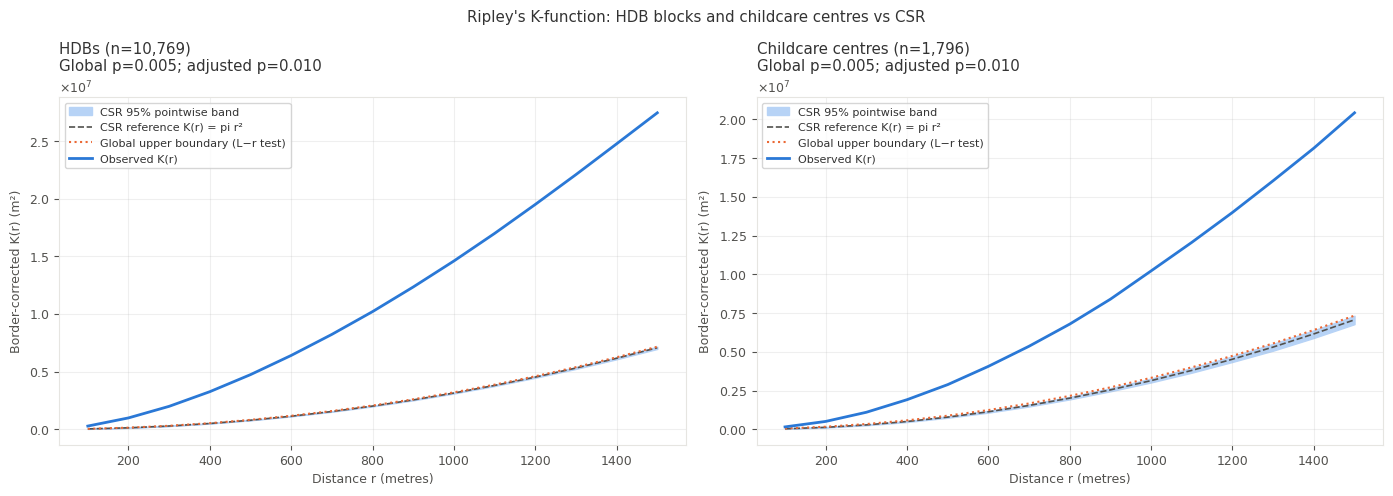

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)
for ax, (name, table) in zip(axes, k_results.items()):
    radius = table.radius_m.to_numpy()
    slug = name.lower().replace(" ", "_")
    # 1. Convert each saved simulation back to K before computing its pointwise band.
    with np.load(K_OUT / f"{slug}_csr_simulations.npz") as saved:
        assert np.array_equal(saved["radii_m"], radius), "Saved simulations and K curve use different radii."
        simulated_k = np.pi * (saved["simulated_L_minus_r_m"] + radius) ** 2
    lower_k, upper_k = np.quantile(simulated_k, [0.025, 0.975], axis=0)
    ax.fill_between(radius, lower_k, upper_k, color="#b7d3f6", label="CSR 95% pointwise band")
    ax.plot(radius, np.pi * radius ** 2, color=INK2, linestyle="--", linewidth=1.2, label="CSR reference K(r) = pi r²")
    # 2. Same global test of max(L-r), expressed as its equivalent K-scale boundary.
    global_upper_k = np.pi * (radius + table.global_upper_2pattern_m.to_numpy()) ** 2
    ax.plot(radius, global_upper_k, color=ORANGE, linestyle=":", label="Global upper boundary (L−r test)")
    ax.plot(radius, table.K_m2, color=BLUE, linewidth=2, label="Observed K(r)")
    ax.set_title(f"{name} (n={k_summary.loc[name, 'analysed_n']:,})\n"
                 f"Global p={k_summary.loc[name, 'global_p']:.3f}; adjusted p={k_summary.loc[name, 'bonferroni_p']:.3f}", loc="left")
    ax.set_xlabel("Distance r (metres)")
    ax.set_ylabel("Border-corrected K(r) (m²)")
    ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0), useMathText=True)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)
fig.suptitle("Ripley's K-function: HDB blocks and childcare centres vs CSR")
fig.tight_layout()
fig.savefig(K_OUT / "k_function_comparison.png", dpi=180, bbox_inches="tight")
plt.show()

## 6. L(r) − r with the CSR band (added 2026-11-10)

L(r) − r = sqrt(K(r)/pi) − r is zero under CSR, so the simulated band becomes a visible ribbon
around zero and the observed excess reads directly in metres: the observed HDB curve reaches
about 1.4 km at r = 1.5 km, the centre curve about 1 km, while the CSR band stays within a few
tens of metres of zero. The dotted line is the global 2.5% boundary; the observed curve crosses it
at the first radius.

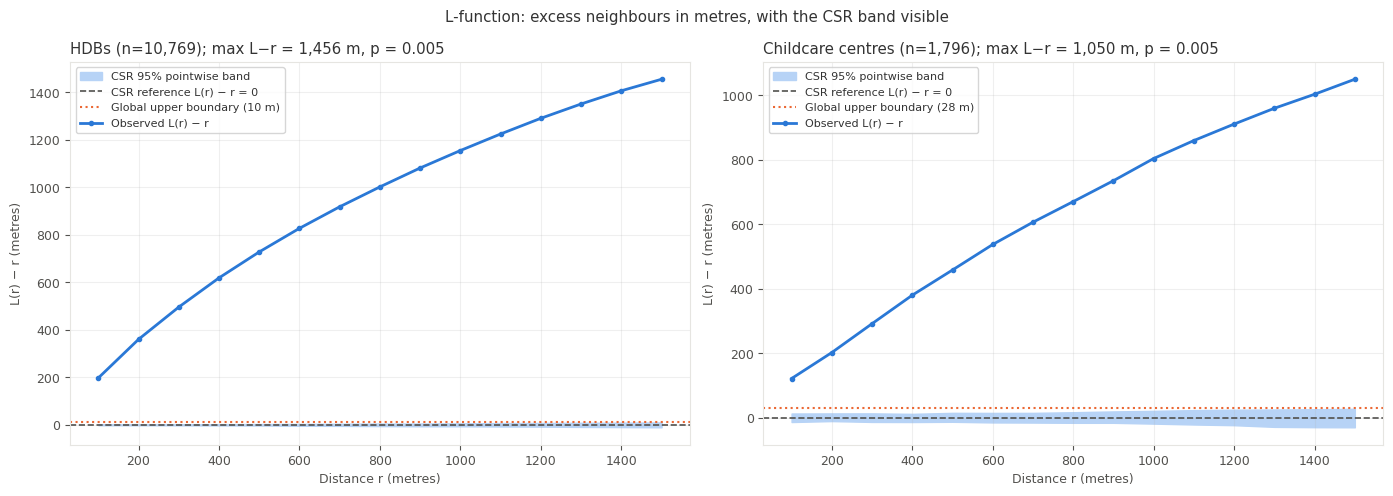

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)
for ax, (name, table) in zip(axes, k_results.items()):
    radius = table.radius_m.to_numpy()
    ax.fill_between(radius, table.CSR_pointwise_lower_m, table.CSR_pointwise_upper_m,
                    color="#b7d3f6", label="CSR 95% pointwise band")
    ax.axhline(0, color=INK2, linestyle="--", linewidth=1.2, label="CSR reference L(r) − r = 0")
    ax.axhline(table.global_upper_2pattern_m.iloc[0], color=ORANGE, linestyle=":",
               label=f"Global upper boundary ({table.global_upper_2pattern_m.iloc[0]:.0f} m)")
    ax.plot(radius, table.L_minus_r_m, color=BLUE, linewidth=2, marker="o", markersize=3, label="Observed L(r) − r")
    ax.set_title(f"{name} (n={k_summary.loc[name, 'analysed_n']:,}); "
                 f"max L−r = {k_summary.loc[name, 'max_L_minus_r_m']:,.0f} m, p = {k_summary.loc[name, 'global_p']:.3f}", loc="left")
    ax.set_xlabel("Distance r (metres)")
    ax.set_ylabel("L(r) − r (metres)")
    ax.legend(fontsize=8, loc="upper left")
    ax.grid(alpha=0.2)
fig.suptitle("L-function: excess neighbours in metres, with the CSR band visible")
fig.tight_layout()
fig.savefig(K_OUT / "l_function_comparison.png", dpi=180, bbox_inches="tight")
plt.show()

## 7. What this does and does not show

Both patterns are clustered at every radius from 100 m to 1.5 km (global p = 0.005, the smallest
value 200 Monte Carlo draws can give; Bonferroni-adjusted 0.01). That is a **descriptive** result:
the baseline is homogeneous CSR over the whole land area, and HDB blocks are obviously not spread
uniformly over reservoirs, airports and industrial estates, so rejecting CSR says that estates
exist, not that anything interesting happens within them. The same goes for the centres: they are
mostly inside HDB estates, so they inherit that clustering. The test does not say that centres and
blocks cluster *together*. Testing co-location would need a **cross-K** (bivariate K₁₂: the
expected number of centres within *r* of a block, against a null of independent labelling or of
random relabelling), or a K with an inhomogeneous intensity fitted to the residential land. That
question is taken up differently in 2.5 and stage 3: supply per child by subzone and the
supply-pressure index, which condition on where the children actually are.

In [9]:
for path in sorted(K_OUT.iterdir()):
    print(f"wrote {path.relative_to(ROOT)}")
print(f"\nk_summary: {len(k_summary)} patterns; curves: {len(K_RADII)} radii each")

wrote output/k_function/childcare_centres_csr_simulations.npz
wrote output/k_function/childcare_centres_k_curve.csv
wrote output/k_function/hdbs_csr_simulations.npz
wrote output/k_function/hdbs_k_curve.csv
wrote output/k_function/k_function_comparison.png
wrote output/k_function/k_summary.csv
wrote output/k_function/l_function_comparison.png

k_summary: 2 patterns; curves: 15 radii each
